In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [23]:
# Load the dataset
df = pd.read_csv("HousingData.csv")

# Display the first 5 records
print("First 5 records:")
display(df.head())

# Display the last 5 records
print("\nLast 5 records:")
display(df.tail())

# Display number of rows and columns
print("\nDataset shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types
print("\nData types:")
print(df.dtypes)

# Display summary statistics
print("\nSummary statistics:")
display(df.describe())

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check total number of missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Fill missing values across all columns using their respective medians
df_clean = df.fillna(df.median())
print("\nMissing values after cleaning:", df_clean.isnull().sum().sum())

# Check duplicate records
print("\nNumber of duplicate records:", df.duplicated().sum())

First 5 records:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2



Last 5 records:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,NaN,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0
505,0.04741,0.0,11.93,0.0,0.573,6.030,NaN,2.5050,1,273,21.0,396.90,7.88,11.9



Dataset shape:
Rows: 506
Columns: 14

Column names:
['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

Data types:
CRIM       float64
ZN         float64
INDUS      float64
CHAS       float64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD          int64
TAX          int64
PTRATIO    float64
B          float64
LSTAT      float64
MEDV       float64
dtype: object

Summary statistics:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,486.000000,486.000000,486.000000,486.000000,506.000000,506.000000,486.000000,506.000000,506.000000,506.000000,506.000000,506.000000,486.000000,506.000000
mean,3.611874,11.211934,11.083992,0.069959,0.554695,6.284634,68.518519,3.795043,9.549407,408.237154,18.455534,356.674032,12.715432,22.532806
std,8.720192,23.388876,6.835896,0.255340,0.115878,0.702617,27.999513,2.105710,8.707259,168.537116,2.164946,91.294864,7.155871,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.081900,0.000000,5.190000,0.000000,0.449000,5.885500,45.175000,2.100175,4.000000,279.000000,17.400000,375.377500,7.125000,17.025000
50%,0.253715,0.000000,9.690000,0.000000,0.538000,6.208500,76.800000,3.207450,5.000000,330.000000,19.050000,391.440000,11.430000,21.200000
75%,3.560263,12.500000,18.100000,0.000000,0.624000,6.623500,93.975000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000



Missing values:
CRIM       20
ZN         20
INDUS      20
CHAS       20
NOX         0
RM          0
AGE        20
DIS         0
RAD         0
TAX         0
PTRATIO     0
B           0
LSTAT      20
MEDV        0
dtype: int64

Total missing values: 120

Missing values after cleaning: 0

Number of duplicate records: 0


In [24]:
# Feature & Target Selection
# Feature (X): RM (Average number of rooms per dwelling)
# Target (y): MEDV (Median value of owner-occupied homes in $1000s)
X = df_clean[['RM']]
y = df_clean['MEDV']

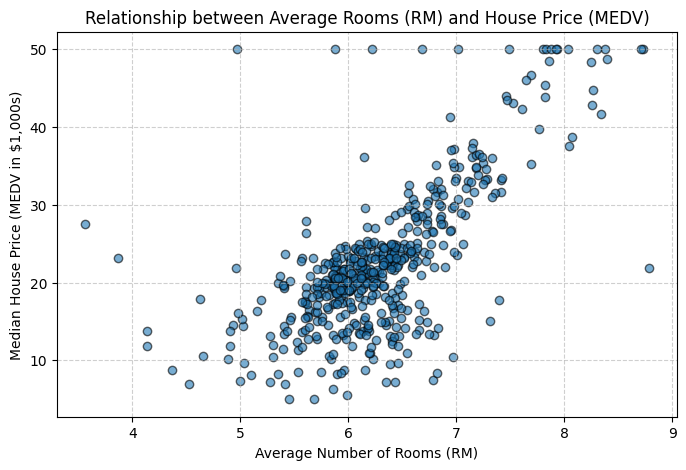

In [25]:
# Visualise Relationship
plt.figure(figsize=(8, 5))
plt.scatter(X, y, alpha=0.6, color='tab:blue', edgecolor='k')
plt.title("Relationship between Average Rooms (RM) and House Price (MEDV)")
plt.xlabel("Average Number of Rooms (RM)")
plt.ylabel("Median House Price (MEDV in $1,000s)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [26]:
# Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("\nData Split: ")
print(f"Training observations: {X_train.shape[0]}")
print(f"Testing observations: {X_test.shape[0]}")


Data Split: 
Training observations: 404
Testing observations: 102


In [27]:
# Train Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

intercept = model.intercept_
slope = model.coef_[0]

print("\nLearned Model Parameters: ")
print(f"Intercept (b): {intercept:.4f}")
print(f"Slope Coefficient (m): {slope:.4f}")
print(f"Equation: MEDV ($1k) = {intercept:.4f} + ({slope:.4f} * RM)")


Learned Model Parameters: 
Intercept (b): -36.2463
Slope Coefficient (m): 9.3483
Equation: MEDV ($1k) = -36.2463 + (9.3483 * RM)


In [28]:
# Generate Test Predictions
y_pred = model.predict(X_test)

results_df = pd.DataFrame({
    'Actual MEDV ($1k)': y_test.values,
    'Predicted MEDV ($1k)': y_pred,
    'Difference ($1k)': y_test.values - y_pred
})

print("\nSample Test Set Predictions: ")
print(results_df.head(10).round(2))


Sample Test Set Predictions: 
   Actual MEDV ($1k)  Predicted MEDV ($1k)  Difference ($1k)
0               23.6                 23.73             -0.13
1               32.4                 26.93              5.47
2               13.6                 19.68             -6.08
3               22.8                 20.45              2.35
4               16.1                 22.62             -6.52
5               20.0                 22.45             -2.45
6               17.8                 19.04             -1.24
7               14.0                 21.47             -7.47
8               19.6                 21.98             -2.38
9               16.8                 20.10             -3.30


In [29]:
# Model Evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nRegression Evaluation Metrics: ")
print(f"Mean Absolute Error (MAE): ${mae * 1000:,.2f} ({mae:.4f} in $1k)")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): ${rmse * 1000:,.2f} ({rmse:.4f} in $1k)")
print(f"R-squared (R² Score): {r2:.4f}")


Regression Evaluation Metrics: 
Mean Absolute Error (MAE): $4,478.34 (4.4783 in $1k)
Mean Squared Error (MSE): 46.1448
Root Mean Squared Error (RMSE): $6,792.99 (6.7930 in $1k)
R-squared (R² Score): 0.3708


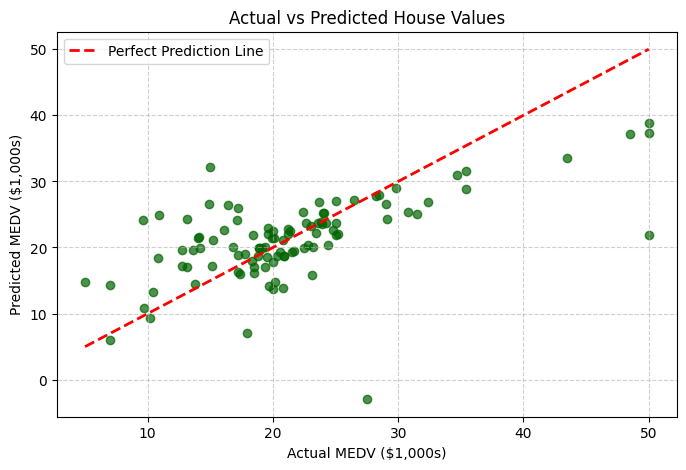

In [30]:
# Visualise Actual vs Predicted
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.7, color='darkgreen')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label="Perfect Prediction Line")
plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual MEDV ($1,000s)")
plt.ylabel("Predicted MEDV ($1,000s)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [31]:
# Predict New Example
# Pass input as a DataFrame with matching column names
new_rooms = pd.DataFrame({'RM': [6.5]})
new_pred = model.predict(new_rooms)[0]

print("\nSingle New Prediction:")
print(f"Input Rooms (RM): 6.5")
print(f"Predicted House Value: ${new_pred * 1000:,.2f} ({new_pred:.2f} in $1,000s)")


Single New Prediction:
Input Rooms (RM): 6.5
Predicted House Value: $24,517.64 (24.52 in $1,000s)
